In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

In [3]:
file_path = "Aktif_Calisma_Veri_Dosyasi/GPT5_NotebookCiktisi_Sirali_cleaned_and_engineered_cars.csv"
df = pd.read_csv(file_path)
print("Veri boyutu:", df.shape)

Veri boyutu: (3810, 553)


## Hedef ve Özellikleri Ayırma

In [4]:
X = df.drop('price', axis=1)
y = df['price']

## Train-Test Split
* Veriyi %80 eğitim, %20 test olarak ayır:

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Özellik Ölçekleme (StandardScaler)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## KNN Modelini Kur ve Eğit

In [7]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsRegressor()

## Tahmin ve Performans Değerlendirmesi

In [8]:
y_pred = knn.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"🔹 Mean Squared Error (MSE): {mse:.2f}")
print(f"🔹 Mean Absolute Error (MAE): {mae:.2f}")
print(f"🔹 R² Score: {r2:.4f}")


🔹 Mean Squared Error (MSE): 15988967795.39
🔹 Mean Absolute Error (MAE): 22514.53
🔹 R² Score: 0.0776


c:\Users\ibo_m\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Sistem belirtilen dosyayı bulamıyor
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ibo_m\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\ibo_m\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ibo_m\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^

## “k” Değerinin Optimizasyonu (Model Ayarı)

* KNN’de en kritik hiperparametre n_neighbors (k) değeridir.
* Bunu GridSearchCV ile otomatik optimize edebilirsin:

In [9]:
from sklearn.model_selection import GridSearchCV

param_grid = {'n_neighbors': range(1, 21)}
grid_search = GridSearchCV(KNeighborsRegressor(), param_grid, cv=5, scoring='r2')
grid_search.fit(X_train_scaled, y_train)

print("En iyi k değeri:", grid_search.best_params_)
print("En iyi R² skoru:", grid_search.best_score_)


En iyi k değeri: {'n_neighbors': 12}
En iyi R² skoru: 0.36100386366098114


## Gerçek vs Tahmin Grafiği

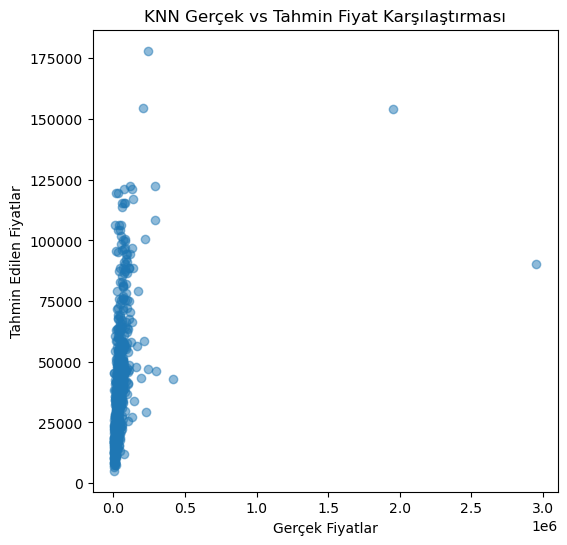

In [10]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Gerçek Fiyatlar")
plt.ylabel("Tahmin Edilen Fiyatlar")
plt.title("KNN Gerçek vs Tahmin Fiyat Karşılaştırması")
plt.show()